# Evaluasi estimasi suhu inti TriaGo

Notebook ini menjelaskan rumus laporan akhir, asal data, dan evaluasi model S0 pada blok satu menit. Notebook membangun ulang kohort dari rekaman VitalDB lokal. Daftar 100 kasus mengikuti eksperimen penggantian kasus 87 dengan 111. Seluruh jendela, simulasi, dan prediksi dihitung ulang. Tabel dan grafik tampil di notebook.

## Rumus laporan akhir

Persamaan (2.5) dan (2.6), §2.2.4, halaman 9 PDF:

$$
\widehat T_c=T_s+\frac{T_s-T_{\mathrm{amb}}}{a+b\,PI}+C_{\mathrm{offset}},
\qquad PI=\frac{AC}{DC}\times100\%.
$$

$AC$ adalah komponen PPG yang berdenyut dan $DC$ adalah komponen dasarnya. Laporan menyebut $a$, $b$, dan $C_{\mathrm{offset}}$ sebagai parameter kalibrasi yang berkaitan dengan resistansi konduktif, sensitivitas perfusi, dan kontribusi metabolik yang belum dimodelkan.

| Variabel | Pada perangkat menurut laporan | Pada evaluasi S0 |
|---|---|---|
| $T_s$ (°C), suhu kulit | Kanal objek MLX90614 membaca permukaan kulit secara inframerah. Sensor dipasang pada penjepit. Uji fungsi sensor dilakukan terpisah di dahi dengan termometer inframerah komersial. | Simulator memakai suhu inti rujukan, lingkungan, dan perfusi untuk membentuk suhu kulit. Respons termal, noise, dan pembulatan sensor menghasilkan kolom t_skin_meas. |
| $T_{\mathrm{amb}}$ (°C), suhu lingkungan | Kanal ambient MLX90614 dibaca bersama kanal objek. Gambar 4.2 menunjukkan contoh 26,25 °C. Bagian laporan yang diperiksa belum menjelaskan pengaturan suhu ruangan. | Lingkungan simulasi berfluktuasi menuju 21,5 °C dan dibatasi pada 18–25 °C. Setelah penambahan noise dan pembulatan ke langkah 0,02 °C, bacaan simulasi disimpan sebagai t_amb. |
| $PI$ (%), indeks perfusi | Rasio AC/DC dari PPG MAX30105. | Kolom pi diturunkan dari sinyal SNUADC/PLETH VitalDB. |
| $T_c$ (°C), suhu inti rujukan | Dasar rujukan angka agregat suhu pada Tabel 4.4 belum terverifikasi. | Kolom t_core berasal dari Solar8000/BT VitalDB. Nilai rujukan per blok adalah rerata t_core. |

**Sumber:** Laporan Akhir GEMASTIK XIX TriaGo, §2.2.4, §2.4.1, Gambar 3.1, §4.2.2, dan Gambar 4.2. Pada folder sumber eksperimen, lihat stage1.py baris 41–53, stage2.py baris 119–138 dan 239–253, serta exp_realistic_amb_loso.py baris 87–131.

## Rumus yang dievaluasi oleh S0

$T_s$, $T_{\mathrm{amb}}$, dan $\overline{PI}$ adalah rerata dari enam jendela 10 detik. Fungsi $\operatorname{clip}$ membatasi nilai ke rentang yang diberikan.

$$
p=\operatorname{clip}(0.10\,\overline{PI},0.005,10.0)
$$
$$
\widehat T_c^{S0}=\operatorname{clip}\!\left(
T_s+\frac{T_s-T_{\mathrm{amb}}}{\max(0.82991+0.97126p,0.1)}
+1.06490,\;30,\;45
\right).
$$

Koefisien tetap berasal dari evaluasi S0. GUI branch main menggunakan persamaan adaptif dengan koefisien dan batas keluaran berbeda (GUI/loading_page.py, baris 148–157). Suhu inti rujukan ikut membentuk suhu kulit simulasi. Hasil S0 berlaku untuk protokol simulasi ini.

**Sumber:** eval_per_subject.py, baris 21–42.

## 1. Inventaris rekaman VitalDB

Kasus 1 sampai 10 memakai berkas .vital yang tersedia. Kasus lain memakai dua kanal VitalDB pada 125 Hz yang sudah disiapkan dalam NPZ: PPG (SNUADC/PLETH) dan suhu inti (Solar8000/BT). NPZ berisi sampel sinyal, tanpa PI, simulasi, atau metrik. Daftar ID mengikuti kohort eksperimen penggantian. Kasus 87 dikeluarkan dan kasus 111 dimasukkan sebelum pemrosesan.

In [14]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy import signal, stats

folder_sumber = Path.home() / "Documents" / "Farid ITS" / "Tugas Akhir" / "scratch" / "temp estimation"
FOLDER_NPZ = Path.home() / "AppData" / "Local" / "Temp"
AMBANG_MAE = 0.35
DAFTAR_KASUS = [
    1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 16, 17, 18, 19, 20, 21, 22,
    24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 40, 41, 42, 43, 44,
    45, 46, 47, 48, 49, 50, 51, 52, 54, 57, 58, 60, 61, 62, 63, 64, 65, 66, 67, 68,
    69, 70, 71, 72, 73, 74, 75, 77, 78, 79, 80, 81, 82, 83, 84, 85, 88, 89, 90, 91,
    92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 103, 104, 105, 106, 107, 108, 109, 110,
    111, 115,
]
assert len(DAFTAR_KASUS) == len(set(DAFTAR_KASUS)) == 100
assert 87 not in DAFTAR_KASUS and 111 in DAFTAR_KASUS

file_kasus = {
    kasus: (folder_sumber / "vital_files" / f"{kasus}.vital" if kasus <= 10
            else FOLDER_NPZ / f"triago_vitaldb_case{kasus}_125hz.npz")
    for kasus in DAFTAR_KASUS
}
hilang = [kasus for kasus, file in file_kasus.items() if not file.is_file()]
if hilang:
    raise FileNotFoundError(f"Rekaman VitalDB lokal belum tersedia untuk kasus: {hilang}")
print(f"Rekaman tersedia: {len(file_kasus)} kasus (10 berkas .vital dan 90 NPZ).")


Rekaman tersedia: 100 kasus (10 berkas .vital dan 90 NPZ).


## 2. Persiapkan jendela dan lakukan EDA

Untuk kasus 1 sampai 10, gunakan pemrosesan rekaman mentah dari stage1.py dan stage2.py serta kriteria seleksi stage3.py. Untuk kasus lain, ikuti pipeline_50_cases.py: saring suhu inti, bentuk segmen, filter PPG, cek kualitas tiap jendela 10 detik, lalu hitung PI. Tabel merangkum suhu inti rujukan sebelum simulasi.

In [15]:
def proses_rekaman(ppg, bt, caseid, target_fs=125.0):
    if len(ppg) < target_fs * 180:
        raise ValueError("Rekaman kasus 111 lebih pendek dari 180 detik.")
    # Physiological gating on core temp (at least 30 valid samples = 60s)
    bt_valid_mask = np.isfinite(bt) & (bt >= 33.0) & (bt <= 45.0)
    if np.sum(bt_valid_mask) < 30:
        raise ValueError(f"Kasus {caseid} tidak memiliki segmen suhu inti yang memenuhi syarat.")

    valid_idx = np.where(bt_valid_mask)[0]
    bt_interp = np.interp(np.arange(len(bt)), valid_idx, bt[valid_idx])

    # Find contiguous segments of valid core temp (gaps <= 30s allowed)
    dt_gap_samples = int(30.0 * target_fs)
    diff_idx = np.diff(valid_idx)
    break_pts = np.where(diff_idx > dt_gap_samples)[0]

    seg_bounds = []
    start_i = valid_idx[0]
    for b in break_pts:
        end_i = valid_idx[b]
        if (end_i - start_i) >= target_fs * 60:
            seg_bounds.append((start_i, end_i))
        start_i = valid_idx[b + 1]
    if (valid_idx[-1] - start_i) >= target_fs * 60:
        seg_bounds.append((start_i, valid_idx[-1]))

    if not seg_bounds:
        raise ValueError(f"Kasus {caseid} tidak memiliki segmen suhu inti yang memenuhi syarat.")

    # 4th-order zero-phase Butterworth filters
    nyq = 0.5 * target_fs
    sos_bp = signal.butter(4, [0.5 / nyq, 10.0 / nyq], btype="bandpass", output="sos")
    sos_lp = signal.butter(4, 0.5 / nyq, btype="lowpass", output="sos")

    win_len = int(10.0 * target_fs)
    epochs = []

    t = np.arange(len(ppg)) / target_fs

    for seg_id, (st, en) in enumerate(seg_bounds):
        seg_ppg = ppg[st:en]
        seg_t = t[st:en]
        seg_bt = bt_interp[st:en]

        # Interpolate NaNs in PPG if any
        if np.isnan(seg_ppg).any():
            v_p_idx = np.where(np.isfinite(seg_ppg))[0]
            if len(v_p_idx) < target_fs * 60:
                continue
            seg_ppg = np.interp(np.arange(len(seg_ppg)), v_p_idx, seg_ppg[v_p_idx])

        # Filter
        try:
            p_bp = signal.sosfiltfilt(sos_bp, seg_ppg)
            p_lp = signal.sosfiltfilt(sos_lp, seg_ppg)
        except Exception:
            continue

        n_win = len(seg_ppg) // win_len
        if n_win < 3:
            continue

        seg_epochs = []
        for w_i in range(n_win):
            w_st = w_i * win_len
            w_en = w_st + win_len
            w_bp = p_bp[w_st:w_en]
            w_lp = p_lp[w_st:w_en]
            w_t = seg_t[w_st:w_en]
            t_center = float(w_t[len(w_t) // 2])
            core_t = float(seg_bt[w_st + len(w_t) // 2])

            dc = float(np.mean(w_lp))
            ac = float(np.percentile(w_bp, 95) - np.percentile(w_bp, 5))

            if dc <= 0.0 or ac <= 0.0:
                continue

            # SQI check
            sd = float(np.std(w_bp, ddof=1))
            sk = float(stats.skew(w_bp))
            kt = float(stats.kurtosis(w_bp, fisher=False))

            sqi_pass = (sk >= 0.10) and (2.0 <= kt <= 6.0) and (0.5 <= sd <= 15.0) and (ac <= 60.0)
            if not sqi_pass:
                continue

            pi_val = (ac / dc) * 100.0
            if pi_val <= 0.0 or pi_val > 150.0:
                continue

            seg_epochs.append({
                "caseid": caseid,
                "seg_id": seg_id,
                "window_idx": w_i,
                "t_center_sec": t_center,
                "t_center_min": round(t_center / 60.0, 2),
                "t_core": round(core_t, 2),
                "ac": round(ac, 3),
                "dc": round(dc, 3),
                "pi": round(pi_val, 2)
            })

        if not seg_epochs:
            continue

        epochs.extend(seg_epochs)

    if len(epochs) < 30:
        raise ValueError(f"Kasus {caseid} memiliki kurang dari 30 jendela valid.")
    return pd.DataFrame(epochs)


# Gunakan pembaca dan DSP asli untuk format lokal .vital.
bytecode_sebelumnya = sys.dont_write_bytecode
sys.dont_write_bytecode = True
sys.path.insert(0, str(folder_sumber))
try:
    from stage2 import process_case_dsp
finally:
    sys.path.pop(0)
    sys.dont_write_bytecode = bytecode_sebelumnya

bagian = []
for kasus, file in file_kasus.items():
    if kasus <= 10:
        hasil_dsp = process_case_dsp(kasus)
        if hasil_dsp["status"] != "OK":
            raise ValueError(f"Kasus {kasus} gagal diproses: {hasil_dsp['status']}")
        data = hasil_dsp["df_epochs"]
        valid = data["sqi_passed"] & data["t_core"].between(33.0, 45.0) & data["pi"].gt(0)
        data = data.loc[valid].assign(caseid=kasus)
        data["t_center_sec"] = data["t_center_sec"].round(2)
        data["t_core"] = data["t_core"].round(2)
        data["pi"] = data["pi"].round(2)
    else:
        with np.load(file, allow_pickle=False) as rekaman:
            ppg, bt = rekaman["ppg"], rekaman["bt"]
        if ppg.ndim != 1 or ppg.shape != bt.shape:
            raise ValueError(f"Kasus {kasus} harus memiliki dua kanal dengan panjang sama.")
        data = proses_rekaman(ppg, bt, kasus)
    if data.empty:
        raise ValueError(f"Kasus {kasus} tidak memiliki jendela yang lolos.")
    bagian.append(data[["caseid", "seg_id", "window_idx", "t_center_sec", "t_core", "pi"]])

jendela_mentah = pd.concat(bagian, ignore_index=True)
print(f"Jendela valid sebelum simulasi: {len(jendela_mentah):,} dari {jendela_mentah['caseid'].nunique()} kasus.")
eda_awal = pd.DataFrame({
    "Suhu inti per jendela 10 detik": jendela_mentah["t_core"].describe(),
    "Rerata suhu inti per kasus": jendela_mentah.groupby("caseid")["t_core"].mean().describe(),
}).T[["count", "min", "25%", "50%", "75%", "max"]]
eda_awal.columns = ["Jumlah", "Minimum", "Q1", "Median", "Q3", "Maksimum"]
display(eda_awal.round(2))


Jendela valid sebelum simulasi: 76,232 dari 100 kasus.


,Jumlah,Minimum,Q1,Median,Q3,Maksimum
Suhu inti per jendela 10 detik,76232.0,33.00,35.50,35.90,36.20,37.70
Rerata suhu inti per kasus,100.0,34.96,35.62,35.92,36.26,37.04


## 3. Simulasikan lingkungan dan suhu kulit untuk seluruh kohort

Terapkan drift suhu lingkungan, respons termal kulit, noise, dan seed per segmen dari exp_realistic_amb_loso.py dan test_case111_replacement.py. Pertahankan pembulatan dua desimal untuk kohort asal serta perlakuan kasus 111 sesuai skrip penggantian.

In [16]:
A_TRUE = 0.574
B_TRUE = 0.850
ALPHA_TRUE = 0.800
TAU_SKIN = 180.0
PI_SCALE = 0.10
MU_AMB = 21.5
THETA_AMB = 1.0 / 1800.0
SIGMA_AMB = 0.05 / np.sqrt(10.0)
AMB_MIN = 18.0
AMB_MAX = 25.0
SENSOR_NETD = 0.05
ADC_STEP = 0.02

sim_dfs = []
for (cid, seg), group in jendela_mentah.groupby(["caseid", "seg_id"], sort=False):
    group = group.sort_values("t_center_sec").copy()
    n = len(group)
    t_sec = group["t_center_sec"].values
    t_core = group["t_core"].values
    pi = group["pi"].values

    rng = np.random.default_rng(2026 + int(cid) * 100 + int(seg))

    t_amb_true = np.zeros(n, dtype=np.float64)
    stat_var = SIGMA_AMB**2 / (2.0 * THETA_AMB)
    t_amb_true[0] = np.clip(rng.normal(MU_AMB, np.sqrt(stat_var)), AMB_MIN, AMB_MAX)

    for k in range(1, n):
        dt = t_sec[k] - t_sec[k - 1]
        if dt <= 0:
            dt = 10.0
        decay = np.exp(-THETA_AMB * dt)
        step_var = stat_var * (1.0 - np.exp(-2.0 * THETA_AMB * dt))
        step_noise = rng.normal(0.0, np.sqrt(max(step_var, 1e-12)))
        val = MU_AMB + (t_amb_true[k - 1] - MU_AMB) * decay + step_noise
        t_amb_true[k] = np.clip(val, AMB_MIN, AMB_MAX)

    amb_noise = rng.normal(0.0, SENSOR_NETD, size=n)
    t_amb_meas = np.round((t_amb_true + amb_noise) / ADC_STEP) * ADC_STEP

    pi_eff = np.maximum(pi * PI_SCALE, 1e-4)
    g_cs = A_TRUE + B_TRUE * np.power(pi_eff, ALPHA_TRUE)
    t_eq = (g_cs * t_core + t_amb_true) / (1.0 + g_cs)

    t_skin = np.zeros(n, dtype=np.float64)
    t_skin[0] = t_eq[0]
    for k in range(1, n):
        dt = t_sec[k] - t_sec[k - 1]
        if dt <= 0.0 or dt > 60.0:
            t_skin[k] = t_eq[k]
        else:
            decay_skin = np.exp(-dt / TAU_SKIN)
            t_skin[k] = t_skin[k - 1] * decay_skin + t_eq[k] * (1.0 - decay_skin)

    skin_noise = rng.normal(0.0, SENSOR_NETD, size=n)
    t_skin_meas = np.round((t_skin + skin_noise) / ADC_STEP) * ADC_STEP

    group["t_amb"] = t_amb_meas if cid == 111 else np.round(t_amb_meas, 2)
    group["t_skin_meas"] = t_skin_meas if cid == 111 else np.round(t_skin_meas, 2)
    sim_dfs.append(group)

jendela = pd.concat(sim_dfs, ignore_index=True)



kunci = ["caseid", "seg_id", "window_idx"]
kolom = [*kunci, "t_core", "t_skin_meas", "t_amb", "pi"]
print(f"Simulasi selesai untuk {jendela['caseid'].nunique()} kasus.")


Simulasi selesai untuk 100 kasus.


## 4. Bentuk blok satu menit dan jalankan S0

Pakai enam jendela 10 detik berurutan dalam kasus dan segmen yang sama. Pastikan tepat 100 kasus memiliki blok lengkap. Koefisien S0 tetap.

In [17]:
if not np.isfinite(jendela[kolom]).all().all():
    raise ValueError("Kohort mengandung nilai kosong atau tak hingga.")
if jendela.duplicated(kunci).any() or (jendela["window_idx"] % 1 != 0).any():
    raise ValueError("Kunci jendela harus unik dan window_idx harus bilangan bulat.")
jendela = jendela.sort_values(kunci)

jendela["blok"] = jendela["window_idx"] // 6
blok = jendela.groupby(["caseid", "seg_id", "blok"], as_index=False).agg(
    jumlah_jendela=("window_idx", "size"),
    awal=("window_idx", "min"), akhir=("window_idx", "max"),
    ts=("t_skin_meas", "mean"), ta=("t_amb", "mean"),
    pi=("pi", "mean"), rujukan=("t_core", "mean"),
)
lengkap = blok["jumlah_jendela"].eq(6) & (blok["akhir"] - blok["awal"]).eq(5)
print(f"Kasus sebelum penyaringan: {jendela['caseid'].nunique()} | Blok lengkap: {lengkap.sum()} | Tidak lengkap: {(~lengkap).sum()}")
blok = blok.loc[lengkap].copy()
if blok["caseid"].nunique() != 100:
    tanpa_blok = sorted(set(jendela["caseid"]) - set(blok["caseid"]))
    raise ValueError(f"Target 100 kasus belum tercapai. Kasus tanpa blok lengkap: {tanpa_blok}")

p = (0.10 * blok["pi"]).clip(0.005, 10.0)
penyebut = (0.82991 + 0.97126 * p).clip(lower=0.1)
blok["prediksi"] = (blok["ts"] + (blok["ts"] - blok["ta"]) / penyebut + 1.06490).clip(30.0, 45.0)
assert len(blok["prediksi"]) == len(blok) and np.isfinite(blok["prediksi"]).all()
blok["galat"] = blok["prediksi"] - blok["rujukan"]
blok["galat_absolut"] = blok["galat"].abs()
hasil_per_kasus = blok.groupby("caseid", as_index=False).agg(
    n_windows=("galat", "size"), t_core_mean=("rujukan", "mean"),
    mae=("galat_absolut", "mean"), bias=("galat", "mean"),
)

Kasus sebelum penyaringan: 100 | Blok lengkap: 10525 | Tidak lengkap: 3788


## 5. Tampilkan EDA dan evaluasi kohort

Skrip penggantian mengevaluasi seluruh kohort dengan koefisien tetap, termasuk kasus yang sebelumnya digunakan untuk pelatihan. Macro MAE memberi bobot sama pada setiap kasus. Pooled MAE memberi bobot sama pada setiap blok. Ambang 0,35 °C adalah ambang eksperimen. Laporan akhir mencantumkan 0,250 °C dan 83%; hubungan langsung dengan hasil hitung ulang belum terverifikasi.

Sebaran rerata suhu inti rujukan (°C):


,Jumlah,Minimum,Q1,Median,Q3,Maksimum
Per kasus,100.0,34.89,35.63,35.91,36.23,36.84
Per blok satu menit,10525.0,33.51,35.54,35.90,36.20,37.40


Total: 100 kasus, 10,525 blok
Macro MAE: 0.2502 °C
Pooled MAE: 0.2294 °C
Bias per blok: -0.0023 °C
Kasus dengan MAE ≤ 0,35 °C: 83/100 (83.0%)
Blok dengan galat absolut ≤ 0,35 °C: 81.8%
Proporsi blok yang memenuhi ambang, rata-rata antar kasus: 80.4%


,caseid,n_windows,t_core_mean,mae,bias
37,42,186,36.0459,0.0777,0.0417
59,68,52,36.1948,0.0906,0.0141
28,32,23,36.3162,0.0923,0.0720
96,109,194,35.6627,0.0946,0.0226
42,47,8,35.6473,0.0970,0.0685
...,...,...,...,...,...
46,51,13,35.9397,0.4695,-0.2085
12,14,44,36.3251,0.5054,-0.2037
66,75,142,36.3020,0.5651,-0.2280
87,99,41,36.4415,0.6415,-0.2007


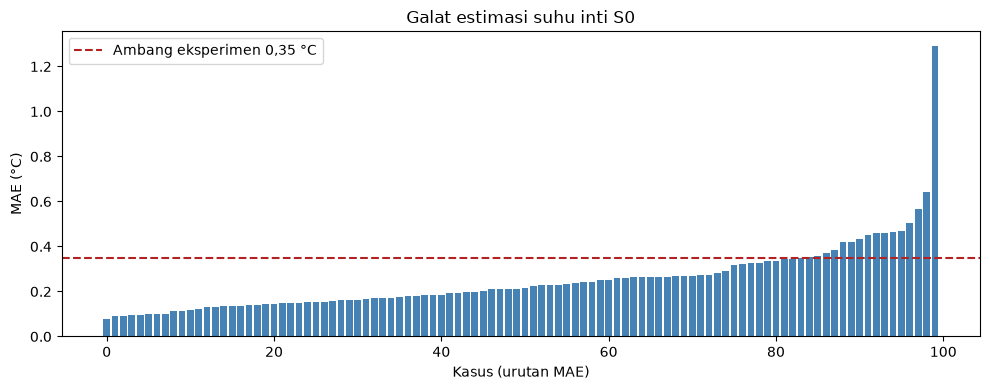

In [18]:
sebaran = pd.DataFrame({
    "Per kasus": hasil_per_kasus["t_core_mean"].describe(),
    "Per blok satu menit": blok["rujukan"].describe(),
}).T[["count", "min", "25%", "50%", "75%", "max"]]
sebaran.columns = ["Jumlah", "Minimum", "Q1", "Median", "Q3", "Maksimum"]
print("Sebaran rerata suhu inti rujukan (°C):")
display(sebaran.round(2))

lolos_kasus = hasil_per_kasus["mae"].le(AMBANG_MAE)
lolos_blok = blok["galat_absolut"].le(AMBANG_MAE)
print(f"Total: {len(hasil_per_kasus)} kasus, {len(blok):,} blok")
print(f"Macro MAE: {hasil_per_kasus['mae'].mean():.4f} °C")
print(f"Pooled MAE: {blok['galat_absolut'].mean():.4f} °C")
print(f"Bias per blok: {blok['galat'].mean():+.4f} °C")
print(f"Kasus dengan MAE ≤ 0,35 °C: {lolos_kasus.sum()}/{len(lolos_kasus)} ({lolos_kasus.mean():.1%})")
print(f"Blok dengan galat absolut ≤ 0,35 °C: {lolos_blok.mean():.1%}")
print(f"Proporsi blok yang memenuhi ambang, rata-rata antar kasus: {lolos_blok.groupby(blok['caseid']).mean().mean():.1%}")

hasil_urut = hasil_per_kasus.sort_values("mae")
display(hasil_urut.round(4))
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib belum tersedia. Tabel evaluasi tetap ditampilkan.")
else:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(np.arange(len(hasil_urut)), hasil_urut["mae"], color="steelblue")
    ax.axhline(AMBANG_MAE, color="firebrick", linestyle="--", label="Ambang eksperimen 0,35 °C")
    ax.set(xlabel="Kasus (urutan MAE)", ylabel="MAE (°C)", title="Galat estimasi suhu inti S0")
    ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)
